In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("../data/processed/superstore_clean.csv", parse_dates=["Order Date", "Ship Date"])
df["Month"] = df["Order Date"].dt.to_period("M").dt.to_timestamp()
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Year,Month Name,Shipping Days,Month
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016,November,3,2016-11-01
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016,November,3,2016-11-01
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016,June,4,2016-06-01
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015,October,7,2015-10-01
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015,October,7,2015-10-01


In [2]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
print("Total Sales :", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Profit Margin:", round(total_profit / total_sales * 100, 2), "%")

Total Sales : 2297200.86
Total Profit: 286397.02
Profit Margin: 12.47 %


               Sales       Profit
Region                           
West     725457.8245  108418.4489
East     678781.2400   91522.7800
South    391721.9050   46749.4303
Central  501239.8908   39706.3625


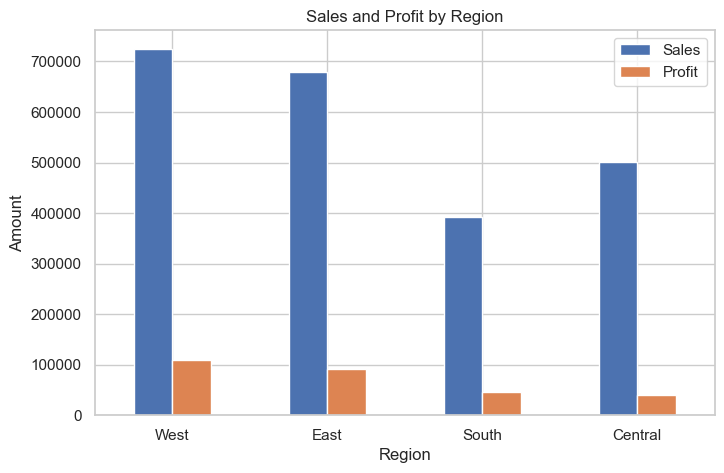

                       Sales       Profit
Category                                 
Furniture        741999.7953   18451.2728
Office Supplies  719047.0320  122490.8008
Technology       836154.0330  145454.9481


In [4]:
# Q1, sales and profit by region and category

region = df.groupby("Region")[["Sales", "Profit"]].sum().sort_values("Profit", ascending=False)
print(region)

region.plot(kind="bar", figsize=(8, 5))
plt.title("Sales and Profit by Region")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.savefig("../images/01_region_sales_profit.png", dpi=150, bbox_inches="tight")
plt.show()

print(df.groupby("Category")[["Sales", "Profit"]].sum())

Sub-Category
Tables      -17725.4811
Bookcases    -3472.5560
Supplies     -1189.0995
Fasteners      949.5182
Machines      3384.7569
Name: Profit, dtype: float64


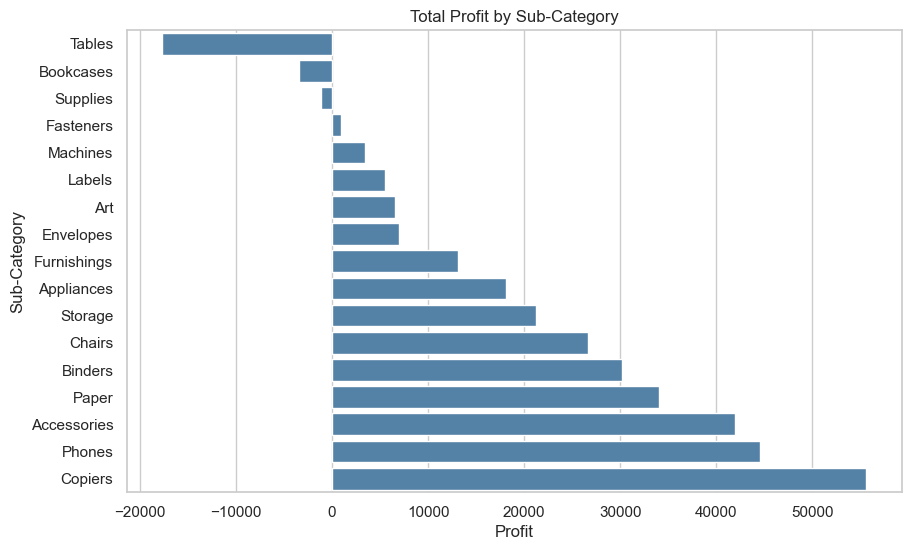

In [5]:
# Q2, loss-making sub-categories

sub = df.groupby("Sub-Category")["Profit"].sum().sort_values()
print(sub.head(5))

plt.figure(figsize=(10, 6))
sns.barplot(x=sub.values, y=sub.index, color="steelblue")
plt.title("Total Profit by Sub-Category")
plt.xlabel("Profit")
plt.savefig("../images/02_subcategory_profit.png", dpi=150, bbox_inches="tight")
plt.show()

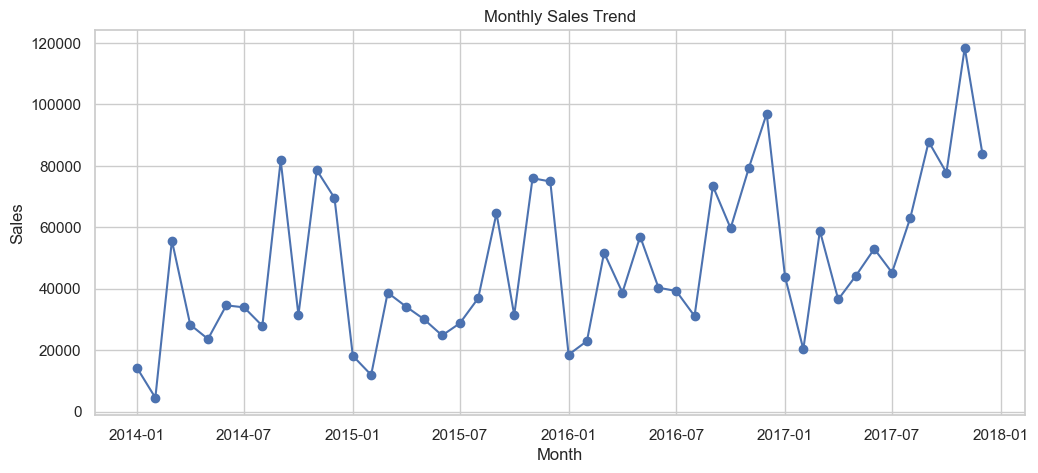

Month Name
November     352461.0710
December     325293.5035
September    307649.9457
Name: Sales, dtype: float64


In [6]:
# Q3, monthly trend

monthly = df.groupby("Month")["Sales"].sum()

plt.figure(figsize=(12, 5))
plt.plot(monthly.index, monthly.values, marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.savefig("../images/03_monthly_trend.png", dpi=150, bbox_inches="tight")
plt.show()

print(df.groupby("Month Name")["Sales"].sum().sort_values(ascending=False).head(3))

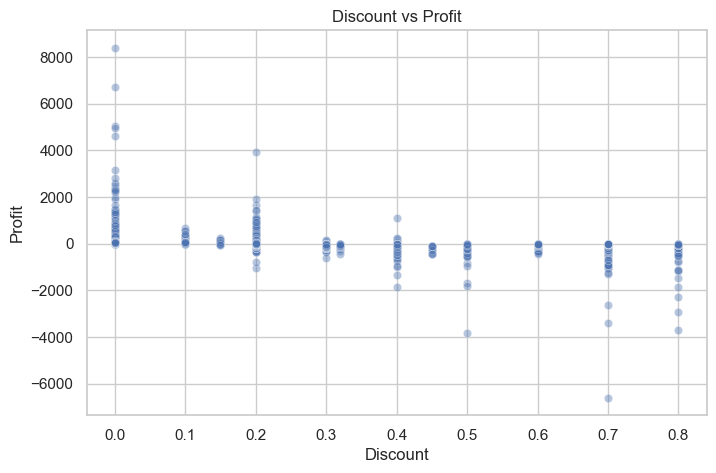

                       sum        mean
Discount Band                         
0%             320987.6032   66.900292
1-20%          100785.4745   26.501571
21-40%         -35817.4655  -77.864055
Above 40%      -99558.5905 -106.708028


In [8]:
# Q4, discount vs profit

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Discount", y="Profit", alpha=0.4)
plt.title("Discount vs Profit")
plt.savefig("../images/04_discount_vs_profit.png", dpi=150, bbox_inches="tight")
plt.show()

df["Discount Band"] = pd.cut(df["Discount"], bins=[-0.01, 0, 0.2, 0.4, 1],
                             labels=["0%", "1-20%", "21-40%", "Above 40%"])
print(df.groupby("Discount Band", observed=True)["Profit"].agg(["sum", "mean"]))

Customer Name
Sean Miller           25043.050
Tamara Chand          19052.218
Raymond Buch          15117.339
Tom Ashbrook          14595.620
Adrian Barton         14473.571
Ken Lonsdale          14175.229
Sanjit Chand          14142.334
Hunter Lopez          12873.298
Sanjit Engle          12209.438
Christopher Conant    12129.072
Name: Sales, dtype: float64


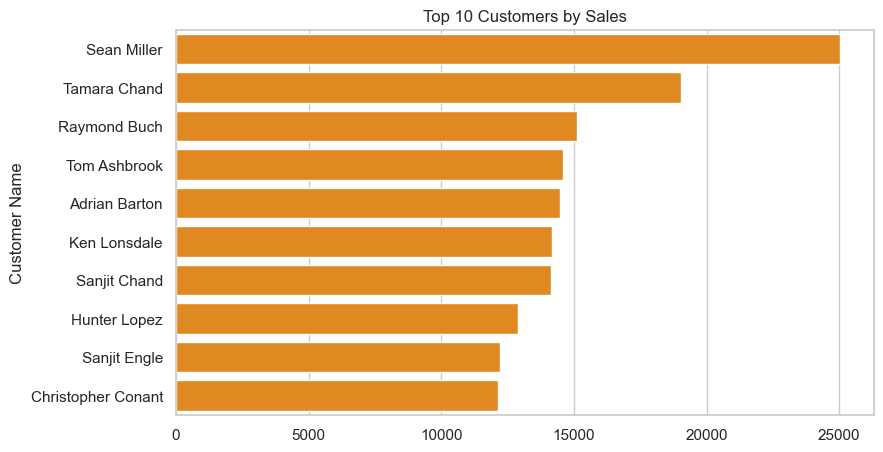

In [10]:
# Q5, top 10 customers

top = df.groupby("Customer Name")["Sales"].sum().sort_values(ascending=False).head(10)
print(top)

plt.figure(figsize=(9, 5))
sns.barplot(x=top.values, y=top.index, color="darkorange")
plt.title("Top 10 Customers by Sales")
plt.savefig("../images/05_top_customers.png", dpi=150, bbox_inches="tight")
plt.show()

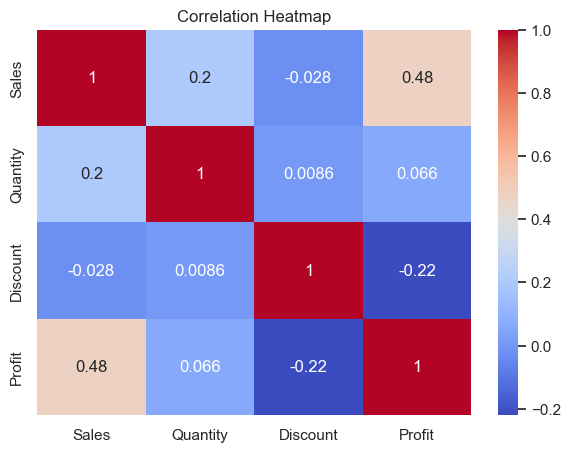

In [11]:
# correlation heatmap

plt.figure(figsize=(7, 5))
sns.heatmap(df[["Sales", "Quantity", "Discount", "Profit"]].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.savefig("../images/06_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

## Key Insights

**Overall:** The store made total sales of 2,297,200.86 and total profit of 286,397.02, a profit margin of 12.47%.

1. **Region:** The West region earned the highest profit (108,418) with a 14.9% margin. The Central region earned the lowest profit (39,706) despite having higher sales than the South, and its margin is only 7.9%.
   *Recommendation: investigate why Central has such a low margin, for example heavy discounting.*

2. **Category:** Technology (145,455) and Office Supplies (122,491) generate most of the profit. Furniture has similar sales (741,999) but only 18,451 profit, a 2.5% margin, compared with about 17% for the other two categories.
   *Recommendation: review pricing and discounts in Furniture.*

3. **Loss-making sub-categories:** Tables lost 17,725, Bookcases lost 3,473 and Supplies lost 1,189. Tables is by far the biggest loss-maker and explains much of Furniture's weak profit.

4. **Discounts:** Average profit per order line falls as discounts rise: +66.90 with no discount, +26.50 at 1-20%, -77.86 at 21-40%, and -106.71 above 40%. Discounts above 20% lose money on average, and orders discounted above 40% lost about 99,559 in total.
   *Recommendation: cap discounts at around 20%.*

5. **Seasonality:** Sales peak in November (352,461), December (325,294) and September (307,650), which points to a strong end-of-year season. These are totals across all years in the data.
   *Recommendation: plan inventory and marketing ahead of Q4.*

6. **Customers:** The top 10 customers generated about 153,811 in sales, only 6.7% of total sales, led by Sean Miller (25,043) and Tamara Chand (19,052). Revenue is spread widely, so the business does not depend on a few big customers.